# The moment-map window-width caveat

**What this notebook is.** `kino.analysis.moments.compute_moment_maps` measures
flux, `Vlos`, and velocity-dispersion maps from any `Datacube` as
flux-weighted spectral moments. Its own module docstring carries a
documented caveat: the dispersion moment is far more noise-fragile than
flux or `Vlos`, and can silently collapse to exactly zero if the cube's
spectral window is too wide relative to the line. This notebook shows
*why*, quantifies it, and demonstrates the (less obvious) flip side: too
**narrow** a window is just as broken, for a different reason. See
`notebooks/06_mangia_datacube_demo.ipynb` for where this was first noticed
in practice, and the development report for the session it was found in.

## 0. Setup

In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

import kino
from kino.analysis.moments import compute_moment_maps, crop_to_line
from kino.io.base import Datacube

rng = np.random.default_rng(seed=0)  # explicit, seeded RNG -- see CLAUDE.md conventions
print("kino", kino.__version__)

kino 0.1.0.dev0


## 1. The three moments, and why dispersion is different

For a background-subtracted weight $w_i = S_i - B$ in spectral channel $i$
at velocity $v_i$:

$$
F = \sum_i w_i, \qquad
V_{\rm los} = \frac{\sum_i w_i v_i}{\sum_i w_i}, \qquad
\sigma_{\rm obs}^2 = \frac{\sum_i w_i (v_i - V_{\rm los})^2}{\sum_i w_i}.
$$

Flux weights every channel by 1; `Vlos` weights it by $v_i$ (linear);
dispersion weights it by $(v_i - V_{\rm los})^2$ -- **quadratic**, and
unbounded as a channel gets further from the line. Away from the line,
$w_i$ is pure noise centred on zero -- harmless for flux and `Vlos`, but a
channel 500 km/s out contributes $\sim 500^2$ as much leverage to the
dispersion sum as one 1 km/s out. Sum that over many such channels in a
wide window and the accumulated noise can dominate the (small, line-only)
true signal in the numerator, driving $\sigma_{\rm obs}^2$ negative --
`compute_moment_maps` clips negative variances to zero, so dispersion
doesn't just get noisy, it collapses to exactly 0.

That's the well-known half of the caveat. The other half, less obvious: a
window that's too **narrow** truncates the line's own wings before they
reach the background, which *biases $\sigma_{\rm obs}^2$ low* -- and a
biased-low variance estimate is just as easily pushed negative (and
clipped to 0) by noise as a noise-dominated wide one is. There is a
sweet spot in between, not just an upper bound.

## 2. One line, three window choices

Same underlying Gaussian line and noise level, drawn independently at
three window widths: too narrow (truncates real signal), a sweet spot,
and too wide (mostly empty, noisy channels). `sigma=30 km/s` is the
line's true (intrinsic + instrumental) width; the window half-width is
quoted in units of that sigma.

/tmp/ipykernel_54789/1640189389.py:31: UserWarning: compute_moment_maps: only 1.7% of the 3001 spectral channels (52 effective) contribute to the stacked spectrum's flux -- the spectral window may be too wide relative to the line. dispersion is especially vulnerable to noise from the rest (see this module's 'window width matters' docstring section). Consider kino.analysis.moments.crop_to_line() first, or pass check_window=False to silence this.
  m = compute_moment_maps(cube, snr_threshold=0, subtract_background=True)


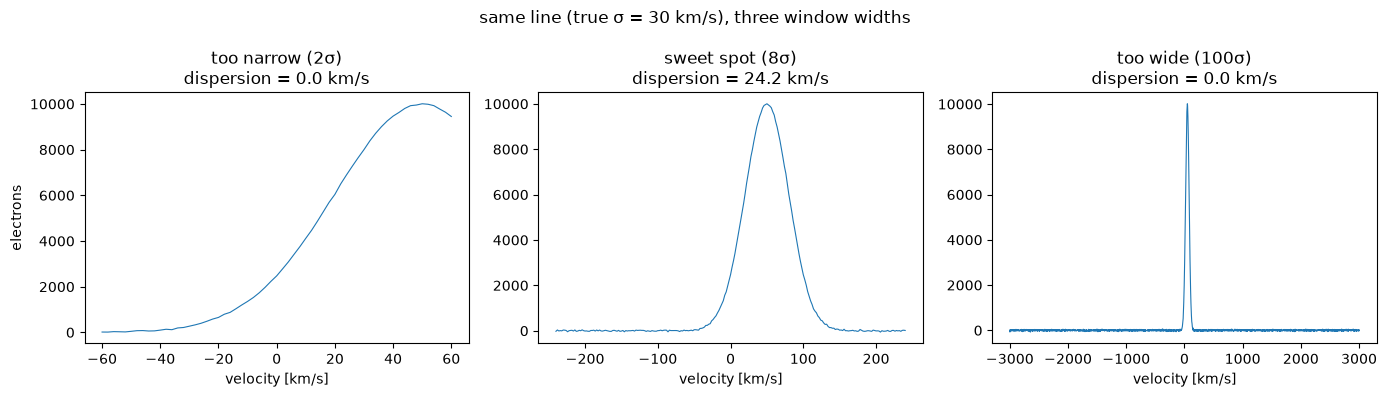

In [2]:
def line_cube(
    v0, sigma, amplitude, background, variance_level, half_range, channel_width, rng=None
):
    """A synthetic single-spaxel Datacube: a Gaussian line's flux, integrated
    per channel (not point-sampled -- matches how a real rendered cube, e.g.
    kino.instruments.ifu.IFU's, stores counts), plus a flat background and
    Gaussian noise of the given per-channel variance."""
    n_spec = int(2 * half_range / channel_width) + 1
    velocity = np.linspace(-half_range, half_range, n_spec) * u.km / u.s
    profile = (
        channel_width * amplitude * np.exp(-0.5 * ((velocity.value - v0) / sigma) ** 2) + background
    )
    if rng is not None:
        profile = profile + rng.normal(0.0, np.sqrt(variance_level), size=n_spec)
    variance = np.full((n_spec, 1, 1), variance_level)
    return Datacube(
        flux=profile[:, np.newaxis, np.newaxis],
        spectral_axis=velocity,
        spectral_kind="velocity",
        pixel_scale=0.1 * u.arcsec,
        redshift=0.0,
        flux_unit=u.electron,
        variance=variance,
    )


V0, SIGMA_TRUE, AMPLITUDE, BACKGROUND, VARIANCE_LEVEL, CHANNEL_WIDTH = (
    50.0,
    30.0,
    5000.0,
    0.0,
    400.0,
    2.0,
)

examples = {"too narrow (2σ)": 2.0, "sweet spot (8σ)": 8.0, "too wide (100σ)": 100.0}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (label, ratio) in zip(axes, examples.items(), strict=False):
    cube = line_cube(
        V0,
        SIGMA_TRUE,
        AMPLITUDE,
        BACKGROUND,
        VARIANCE_LEVEL,
        ratio * SIGMA_TRUE,
        CHANNEL_WIDTH,
        rng=rng,
    )
    m = compute_moment_maps(cube, snr_threshold=0, subtract_background=True)
    v = cube.spectral_axis.to_value(u.km / u.s)
    ax.plot(v, cube.flux[:, 0, 0], lw=0.8)
    ax.set_title(f"{label}\ndispersion = {m.dispersion[0, 0]:.1f} km/s")
    ax.set_xlabel("velocity [km/s]")
axes[0].set_ylabel("electrons")
fig.suptitle(f"same line (true σ = {SIGMA_TRUE:.0f} km/s), three window widths")
fig.tight_layout()

## 3. The mechanism: what actually dominates the sum

For the "too wide" case above, plot each channel's contribution to the
dispersion numerator, $w_i (v_i - V_{\rm los})^2$, against velocity. The
line itself sits in a handful of channels near $v=50$; everything else is
noise -- but multiplied by a $(v-V_{\rm los})^2$ that grows without bound,
a few of those far-out noise channels can outweigh the entire line.

sum over near-line channels:  3.364e+08
sum over far-from-line channels: -1.217e+09
total (this is the numerator of sigma^2, before dividing by sum(w)): -8.808e+08


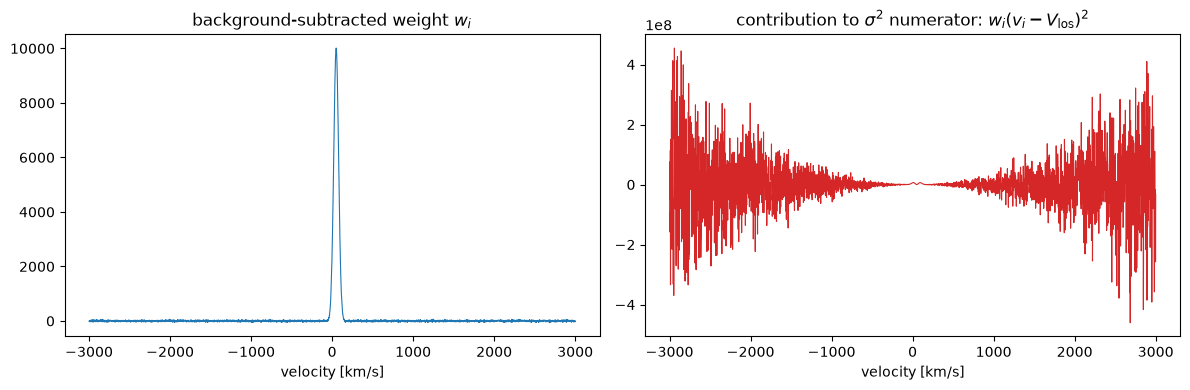

In [3]:
wide_cube = line_cube(
    V0,
    SIGMA_TRUE,
    AMPLITUDE,
    BACKGROUND,
    VARIANCE_LEVEL,
    100.0 * SIGMA_TRUE,
    CHANNEL_WIDTH,
    rng=rng,
)
v = wide_cube.spectral_axis.to_value(u.km / u.s)
background_est = np.median(wide_cube.flux[:, 0, 0])
w = wide_cube.flux[:, 0, 0] - background_est
vlos_est = np.sum(w * v) / np.sum(w)
contribution = w * (v - vlos_est) ** 2

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(v, w, lw=0.8)
axes[0].set_title("background-subtracted weight $w_i$")
axes[0].set_xlabel("velocity [km/s]")

axes[1].plot(v, contribution, lw=0.8, color="tab:red")
axes[1].set_title(r"contribution to $\sigma^2$ numerator: $w_i (v_i - V_{\rm los})^2$")
axes[1].set_xlabel("velocity [km/s]")
fig.tight_layout()

near_line = np.abs(v - V0) < 5 * SIGMA_TRUE
print(f"sum over near-line channels:  {contribution[near_line].sum():.3e}")
print(f"sum over far-from-line channels: {contribution[~near_line].sum():.3e}")
print(
    f"total (this is the numerator of sigma^2, before dividing by sum(w)): {contribution.sum():.3e}"
)

## 4. The fix: `crop_to_line` and the built-in diagnostic

Two mitigations now ship alongside this caveat. `kino.analysis.moments.crop_to_line`
crops a cube's spectral axis to a window around a given centre before you
ever call `compute_moment_maps` -- the safe path, made the easy path.
`compute_moment_maps` itself also runs a cheap, cube-level diagnostic by
default (`check_window=True`): it stacks the cube's flux over space,
estimates what fraction of channels are "effectively" carrying the signal
(a participation-ratio calculation, `n_eff / n_total`), and emits a
`UserWarning` if that fraction looks too small -- exactly the "too wide"
failure mode above. It does **not** catch the "too narrow" failure (no
comparably robust signal to check for that one automatically), which is
why the too-narrow panel in Section 2 raised no warning even though its
dispersion was equally wrong.

In [4]:
wide_cube = line_cube(
    V0,
    SIGMA_TRUE,
    AMPLITUDE,
    BACKGROUND,
    VARIANCE_LEVEL,
    100.0 * SIGMA_TRUE,
    CHANNEL_WIDTH,
    rng=rng,
)

print("uncropped (100 sigma half-width):")
m_wide = compute_moment_maps(wide_cube, snr_threshold=0, subtract_background=True)
print(f"  dispersion = {m_wide.dispersion[0, 0]:.1f} km/s  (warning fires above, if any)")

cropped = crop_to_line(wide_cube, center=V0 * u.km / u.s, half_width=8 * SIGMA_TRUE * u.km / u.s)
print(f"\ncropped to +/- 8 sigma ({cropped.shape[0]} of {wide_cube.shape[0]} channels kept):")
m_cropped = compute_moment_maps(cropped, snr_threshold=0, subtract_background=True)
disp_val = m_cropped.dispersion[0, 0]
print(f"  dispersion = {disp_val:.1f} km/s  (no warning; true sigma = {SIGMA_TRUE:.0f})")

uncropped (100 sigma half-width):
  dispersion = 0.0 km/s  (warning fires above, if any)

cropped to +/- 8 sigma (241 of 3001 channels kept):
  dispersion = 25.2 km/s  (no warning; true sigma = 30)


/tmp/ipykernel_54789/1359137063.py:4: UserWarning: compute_moment_maps: only 1.7% of the 3001 spectral channels (52 effective) contribute to the stacked spectrum's flux -- the spectral window may be too wide relative to the line. dispersion is especially vulnerable to noise from the rest (see this module's 'window width matters' docstring section). Consider kino.analysis.moments.crop_to_line() first, or pass check_window=False to silence this.
  m_wide = compute_moment_maps(wide_cube, snr_threshold=0, subtract_background=True)


## 5. Systematic sweep: fraction collapsed vs. window width

Hold the line and noise fixed, vary only the window's half-width (in
units of the true sigma), and run 300 independent noisy realisations at
each width. Three things to track: how often dispersion collapses to
exactly 0, what it recovers when it doesn't, and how `Vlos` degrades over
the same range (it does, but never *collapses* -- a different, milder
failure mode). `check_window=False` throughout this sweep -- we're
deliberately probing bad windows here, so the warning from Section 4 would
just be 5400 lines of expected noise.

In [5]:
ratios = [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, 30, 50, 75, 100, 150, 200]
n_mc = 300

frac_zero = np.zeros(len(ratios))
disp_median = np.full(len(ratios), np.nan)
disp_std = np.full(len(ratios), np.nan)
vlos_std = np.zeros(len(ratios))

for i, ratio in enumerate(ratios):
    half_range = ratio * SIGMA_TRUE
    disp_draws, vlos_draws = [], []
    for _ in range(n_mc):
        cube = line_cube(
            V0,
            SIGMA_TRUE,
            AMPLITUDE,
            BACKGROUND,
            VARIANCE_LEVEL,
            half_range,
            CHANNEL_WIDTH,
            rng=rng,
        )
        m = compute_moment_maps(cube, snr_threshold=0, subtract_background=True, check_window=False)
        disp_draws.append(m.dispersion[0, 0])
        vlos_draws.append(m.vlos[0, 0])
    disp_draws = np.array(disp_draws)
    vlos_std[i] = np.std(vlos_draws)
    frac_zero[i] = np.mean(disp_draws == 0)
    nonzero = disp_draws[disp_draws > 0]
    if len(nonzero):
        disp_median[i] = np.median(nonzero)
        disp_std[i] = np.std(nonzero)

print("swept", len(ratios), "window widths x", n_mc, "realisations each")

swept 18 window widths x 300 realisations each


best-behaved window in this sweep: half-width = 8 x sigma (frac_zero=0.00)


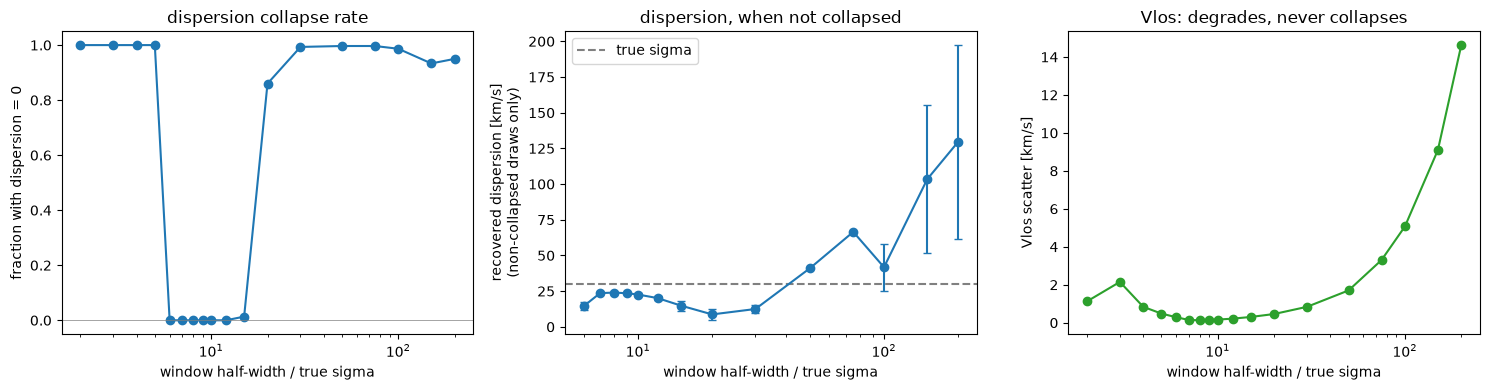

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(ratios, frac_zero, "o-")
axes[0].set_xscale("log")
axes[0].set_xlabel("window half-width / true sigma")
axes[0].set_ylabel("fraction with dispersion = 0")
axes[0].set_title("dispersion collapse rate")
axes[0].axhline(0, color="gray", lw=0.5)

axes[1].errorbar(ratios, disp_median, yerr=disp_std, fmt="o-", capsize=3)
axes[1].axhline(SIGMA_TRUE, color="gray", ls="--", label="true sigma")
axes[1].set_xscale("log")
axes[1].set_xlabel("window half-width / true sigma")
axes[1].set_ylabel("recovered dispersion [km/s]\n(non-collapsed draws only)")
axes[1].set_title("dispersion, when not collapsed")
axes[1].legend()

axes[2].plot(ratios, vlos_std, "o-", color="tab:green")
axes[2].set_xscale("log")
axes[2].set_xlabel("window half-width / true sigma")
axes[2].set_ylabel("Vlos scatter [km/s]")
axes[2].set_title("Vlos: degrades, never collapses")

fig.tight_layout()

best = ratios[np.nanargmin(np.where(frac_zero == 0, np.abs(disp_median - SIGMA_TRUE), np.inf))]
print(
    f"best-behaved window in this sweep: half-width = {best} x sigma "
    f"(frac_zero={frac_zero[ratios.index(best)]:.2f})"
)

## 6. Does higher S/N save a too-wide window?

Only partially. Raising the line's amplitude (brighter source, same
per-channel noise) delays the collapse a little, but doesn't rescue it --
because what actually matters is the *total number of noisy channels*
being summed over, which grows with the window regardless of how bright
the line itself is.

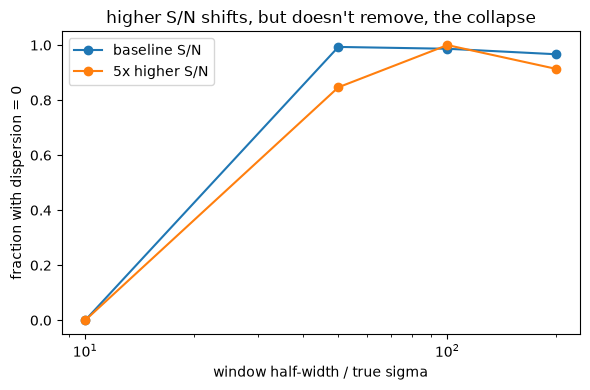

In [7]:
wide_ratios = [10, 50, 100, 200]
fig, ax = plt.subplots(figsize=(6, 4))
for amp_mult, label in [(1, "baseline S/N"), (5, "5x higher S/N")]:
    fz = []
    for ratio in wide_ratios:
        n_zero = 0
        for _ in range(150):
            cube = line_cube(
                V0,
                SIGMA_TRUE,
                AMPLITUDE * amp_mult,
                BACKGROUND,
                VARIANCE_LEVEL,
                ratio * SIGMA_TRUE,
                CHANNEL_WIDTH,
                rng=rng,
            )
            m = compute_moment_maps(
                cube, snr_threshold=0, subtract_background=True, check_window=False
            )
            n_zero += m.dispersion[0, 0] == 0
        fz.append(n_zero / 150)
    ax.plot(wide_ratios, fz, "o-", label=label)
ax.set_xscale("log")
ax.set_xlabel("window half-width / true sigma")
ax.set_ylabel("fraction with dispersion = 0")
ax.set_title("higher S/N shifts, but doesn't remove, the collapse")
ax.legend()
fig.tight_layout()

## What's next

- **Practical rule** (consistent with the sweep above and with
  `notebooks/06_mangia_datacube_demo.ipynb`'s working configuration): size
  the spectral window to a handful of line-widths on each side of the
  line -- wide enough that the true wings are fully inside it, narrow
  enough that pure-noise channels don't dominate the sum. Neither bound
  is exact; both depend on S/N, so check (as this notebook does) rather
  than assume.
- This caveat, the practical rule, and the two mitigations
  (`crop_to_line`, the built-in `check_window` diagnostic) are documented
  in `kino.analysis.moments`'s own module docstring and in `CLAUDE.md`, so
  future callers see it without having to rediscover it.
- The diagnostic only catches the too-wide failure; a too-narrow window
  still needs a human (or a future, more careful heuristic) to notice. A
  more robust alternative for a real analysis pipeline would replace the
  raw second moment with a windowed/apodised weight (down-weighting
  far-from-line channels smoothly, rather than a hard cutoff) or an actual
  line-profile fit -- out of scope for `kino.analysis.moments` today (see
  its module docstring: "this is not a line-fitting pipeline"), but a
  natural Phase 6 follow-up if raw moments prove too fragile for the
  injection-recovery suites in `TEST_DATA.md`.